# Aula 6 - M?todos de Ensemble: Bagging e Random Forest

_________________

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# desabilita os warnings
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split

____
____
____

## 1) M?todos de Ensemble


H? uma classe de algoritmos de Machine Learning, os chamados **m?todos de ensemble**, que tem como objetivo **combinar as predi??es de diversos estimadores mais simples** para gerar uma **predi??o final mais robusta**

Os m?todos de ensemble costuman ser divididos em duas classes:

- **M?todos de m?dia**: t?m como procedimento geral construir diversos estimadores independentes, e tomar a m?dia de suas predi??es como a predi??o final. O principal objetivo do m?todo ? reduzir **vari?ncia**, de modo que o modelo final seja melhor que todos os modelos individuais. Ex.: **random forest.**
<br>

- **M?todos de boosting**: t?m como procedimento geral a constru??o de estimadores de forma sequencial, de modo que estimadores posteriores tentam reduzir o **vi?s** do estimador conjunto, que leva em considera??o estimadores anteriores. Ex.: **adaboost**.

H?, ainda, uma terceira classe de m?todo de ensemble, o chamado [stacking ensemble](https://machinelearningmastery.com/stacking-ensemble-machine-learning-with-python/), que consiste em "empilhar" modelos de modo a produzir a mistura. N?o veremos esta modalidade em detalhes, mas deixo como sugest?o para estudos posteriores! :)

Para mais detalhes sobre m?todos de ensemble no contexto do sklearn, [clique aqui!](https://scikit-learn.org/stable/modules/ensemble.html)

Na aula de hoje, vamos conhecer em detalhes os procedimentos de bagging, explorando, particularmente, a **random forest**. Algumas abordagens de boosting ser?o exploradas em Machine Learning II.

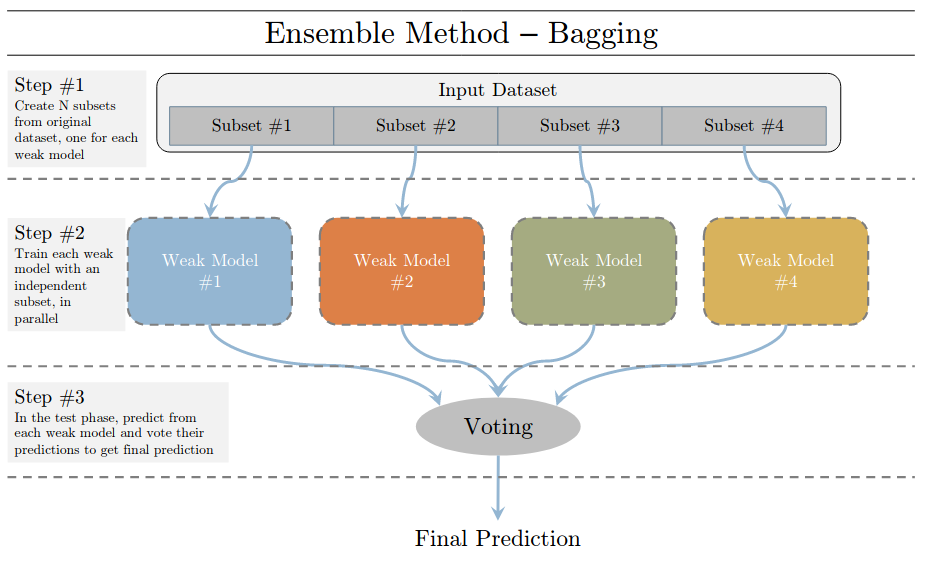<img src='images/bagging.png' style="width:900px"  text="http://cheatsheets.aqeel-anwar.com" />  

_________
_______
_________

## 2) Bagging & Random Forest

Uma t?cnica muito interessante (e muito perform?tica!) baseada em ?rvores ? o **Random Forest**.

Neste m?todo, s?o criadas varias **?rvores diferentes e independentes entre si**, atrav?s de um processo **aleat?rio**, e a predi??o final ? tomada atrav?s da m?dia das predi??es individuais!

<img src="https://i.ytimg.com/vi/goPiwckWE9M/maxresdefault.jpg" width=700>

O Random Forest utiliza os conceitos de **bootstrapping** e **aggregation** (ou ent?o, o procedimento composto **bagging**) para criar um modelo composto que ? melhor que uma ?nica ?rvore!

<img src="https://c.mql5.com/2/33/image1__1.png" width=600>

Vamos entrender um pouco melhor cada componente do m?todo!

### Bootstrapping

O procedimento de **bootstrapping** ? utilizado no contexto do random forest para gerar os chamados **bootstrapped datasets**.

A ideia ? bem simples! Para a cria??o de cada bootstrapped dataset, primeiro:

> Selecionamos **aleatoriamente com reposi??o** algumas linhas da base original. Isso gera um novo dataset (reamostrado), chamado de **bootstrapped dataset**. O n?mero de linhas do dataset reamostrado ? control?vel.

Logo ap?s, fazemos uma ?rvore de decis?o **treinada neste dataset reamostrado**. Mas com um detalhe:

> Usamos apenas um **subconjunto aleat?rio das features** em cada avalia??o de quebras (isso equivale ao `splitter="random"`). A quantidade de features a serem consideradas ? control?vel.

Com isso, muitas ?rvores s?o geradas (a quantidade tamb?m ? control?vel), cada uma seguindo o procedimento de bootstrap!

Note que o o procedimento de bootstrapping introduz **duas fontes de aleatoriedade**, cujo objetivo ? **diminuir a vari?ncia** (tend?ncia a overfitting) do modelo.

De fato, ?rvores individuais s?o facilmente overfitadas, como discutimos em aula (lembre-se da grande flexibilidade da hip?tese em encontrar condi??es favor?veis ? aprendizagem dos ru?dos!).

Com esta aleatoriza??o introduzida pelo bootstrapping, o objetivo ? que as ?rvores constru?das sejam **independentes**, de modo que **os erros cometidos por cada uma sejam independentes**. 

Deste modo, se considerarmos as previs?es isoladas e de alguma forma **agregar** as previs?es, a expectativa ? que o modelo final seja **menos propenso a overfitting**! Mas, uma pergunta natural ?: o que ? essa "agraga??o"? Aqui entra o segundo elemento do bagging...

### Aggregation

Entendemos como o bootstrap ? utilizado para gerar v?rias ?rvores independentes. 

Ent?o, quando temos uma nova observa??o para atribuir o target, passamos as features **por cada uma das ?rvores**, e, naturalmente, cada ?rvore produz **o seu target**, que pode muito bem n?o ser o mesmo!

A **agrega??o** ? utilizada para tomar a decis?o final:

> No caso de classifica??o, a classe final ? atribu?da como **a classe majorit?ria**, isso ?, **a classe que foi o output $\hat{y}$ mais vezes dentre todas as ?rvores**;

> No caso de regress?o, o valor final ? atribu?do como **a m?dia dos valores preditos $\hat{y}$ por cada ?rvore**.

Note que em ambos os casos, o procedimento de agrega??o pode ser visto como uma **m?dia**, e o sklearn deixa isso expl?cito: "*In contrast to the original publication, the scikit-learn implementation combines classifiers by averaging their probabilistic prediction, instead of letting each classifier vote for a single class.*"

Tomando a m?dia como procedimento de agrega??o, a expectativa ? que **alguns erros sejam anulados**, garantindo uma previs?o final **mais est?vel e mais generaliz?vel**, dado que os ru?dos s?o eliminados.

Juntando o bootstrapping com o aggregation, temos ent?o o...

### Bagging

> Bagging: **b**ootstrap **agg**regat**ing**

Esquematicamente:

<img src=https://media.geeksforgeeks.org/wp-content/uploads/20210707140912/Bagging.png width=500>

As classes do random forest s?o:

- [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html#sklearn.ensemble.RandomForestClassifier)

- [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor)

Ambos os m?todos t?m hiperpar?metros similares aos hiperpar?metros das ?rvores convencionais, aplicados a cada uma das ?rvores independentes.

Al?m destes, h? dois hiperpar?metros bem importantes, referentes ao m?todo de ensemble em si:

- `n_estimators` : controla quantas ?rvores independentes ser?o constru?das (i.e., o n?mero de ?rvores na floresta). Em geral, quanto mais ?rvores melhor (mas mais tempo vai demorar). Al?m disso, depois de uma determinade quantidade de ?rvores, os resultados v?o parar de melhorar, pois h? um limite para o bootstrap: depois de uma certa quantidade, as ?rvores deixam de ser t?o independentes assim...
<br>

- `max_features`: o n?mero de features no subconjunto aleat?rio de candidata a serem utilizadas em cada quebra. Quanto menor for o valor, mais conseguimos reduzir o overfitting, mas o underfitting ? favorecido. Uma boa heur?stica ? `max_features=None` para regress?o e `max_features="sqrt"`para classifica??o, embora estrat?gias diferentes podem (e devem) ser testadas com o CV.


___

Para uma explica??o bem visual sobre o funcionamento deste m?todo, sugiro os v?deos do canal [StatQuest](https://www.youtube.com/watch?v=J4Wdy0Wc_xQ). 

Obs.: toda a [playlist de machine learning](https://www.youtube.com/playlist?list=PLblh5JKOoLUICTaGLRoHQDuF_7q2GfuJF) ? muit?ssimo interessante, com v?deos super claros e ilustrativos! Al?m disso, h? outros v?deos de estat?stica que s?o muito bons! Este ? um dos melhores canais no youtube para se aprender de forma clara e descontra?da sobre estat?stica e machine learning!

_____________

Agora, vamos ver o Random Forest em a??o!

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.ensemble import RandomForestClassifier

___
Vamos construir o passo a passo do pipeline do ciclo de modelagem, do pr?-processamento ? avalia??o do modelo, e veremos como executar estas etapas utilizando a ferramenta que estudamos na ?ltima aula: o Pipeline.

#### 1. Divis?o dos dados em treinamento e teste

In [ ]:
df = pd.read_csv("german_credit_data.csv", index_col=0)

X = df.drop(columns="Risk")
y = df["Risk"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#### 2. Tratamento de dados num?ricos e categ?ricos

##### 2.1. Dados num?ricos

In [ ]:
df.info()

Vamos assumir que preencheremos valores nulos, nas colunas num?ricas, com a m?dia. Podemos utilizar o [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html) para faz?-lo!

In [ ]:
# O SimpleImputer segue a mesma l?gica de outros "transformers" que estudamos, como os de normaliza??o
sim_imp = SimpleImputer(strategy = "mean").fit(X_train.select_dtypes(include = np.number))
X_train_num = sim_imp.transform(X_train.select_dtypes(include = np.number))
X_test_num = sim_imp.transform(X_test.select_dtypes(include = np.number))

# Scaling dos dados
scaler = StandardScaler()
scaler.fit(X_train_num)
X_train_num = scaler.transform(X_train_num)
X_test_num = scaler.transform(X_test_num)


In [ ]:
np.isnan(df2).sum()

In [ ]:
X_train_num[:,0:10]

##### 2.2. Dados categ?ricos

In [ ]:
# Preenchimento de valores nulos com "unknown"
sim_inp_cat = SimpleImputer(strategy = "constant", fill_value = "unknown")
sim_inp_cat.fit(X_train.select_dtypes(exclude = np.number))

X_train_cat = sim_inp_cat.transform(X_train.select_dtypes(exclude = np.number))
X_test_cat = sim_inp_cat.transform(X_test.select_dtypes(exclude = np.number))

# One-hot encoding (similar ao get_dummies do pandas!)
encoder = OneHotEncoder(sparse_output = False).fit(X_train_cat)
X_train_cat = encoder.transform(X_train_cat)
X_test_cat = encoder.transform(X_test_cat)

In [ ]:
X_train_cat.shape

##### 2.3. Juntando todas as features

In [ ]:
X_train_num.shape

In [ ]:
X_train_final = np.concatenate((X_train_num, X_train_cat), axis = 1)
X_test_final = np.concatenate((X_test_num, X_test_cat), axis = 1)

In [ ]:
X_train_final.shape

#### 3. Treinamento e avalia??o do modelo

In [ ]:
# Treinamento do modelo
rf = RandomForestClassifier(random_state = 42)
rf.fit(X_train_final, y_train)

# Avalia??o no conjunto de treino
print("\n===== Avalia??o no conjunto de treinamento =====\n")
y_pred_train = rf.predict(X_train_final)
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train)
plt.show()
print(classification_report(y_train, y_pred_train))

# Avalia??o no conjunto de teste
print("\n===== Avalia??o no conjunto de teste =====\n")
y_pred_test = rf.predict(X_test_final)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test)
plt.show()
print(classification_report(y_test, y_pred_test))


___

Deste modo, temos uma aplica??o do nosso classificador Random Forest!

No entanto, vale notar como todas as etapas de processamento foram trabalhosas, n?o ? mesmo? Podemos simplificar consideravelmente o processo apenas **elencando** os passos que queremos executar, embutindo-os em um Pipeline! Vejamos abaixo:

### Aplicando o Pipeline

In [ ]:
# LEITURA DOS DADOS E SEPARA??O EM TREINO E TESTE
df = pd.read_csv("german_credit_data.csv", index_col=0)

X = df.drop(columns="Risk")
y = df["Risk"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ==========================================================
# TRATAMENTO DE FEATURES NUM?RICAS
pipe_features_num = Pipeline([("input_num", SimpleImputer(strategy="mean")),
                              ("std", StandardScaler())])

features_num = X_train.select_dtypes(include=np.number).columns.tolist()

# ==========================================================
# TRATAMENTO DE FEATURES CATEG?RICAS
pipe_features_cat = Pipeline([("input_cat", SimpleImputer(strategy="constant", fill_value="unknown")),
                              ("onehot", OneHotEncoder())])

features_cat = X_train.select_dtypes(exclude=np.number).columns.tolist()

# ==========================================================
# APLICA??O DE TRANSFORMA??ES NAS COLUNAS
pre_processador = ColumnTransformer([("transf_num", pipe_features_num, features_num),
                                     ("transf_cat", pipe_features_cat, features_cat)])

# pipeline final
pipe_rf = Pipeline([("pre_processador", pre_processador),
                    ("rf", RandomForestClassifier(random_state=42))])

# Ajustamos nosso pipeline aos nossos dados
pipe_rf.fit(X_train, y_train)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [ ]:
# ============================================

print("\nM?tricas de avalia??o de treino:")

y_pred_train = pipe_rf.predict(X_train)

print(confusion_matrix(y_train, y_pred_train))

ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train)
plt.show()

print(classification_report(y_train, y_pred_train))


# ============================================

print("\nM?tricas de avalia??o de teste:")

y_pred_test = pipe_rf.predict(X_test)

print(confusion_matrix(y_test, y_pred_test))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test)
plt.show()

print(classification_report(y_test, y_pred_test))

Vejam que o resultado ? exatamente o mesmo! 

Contudo, com a aplica??o do Pipeline, podemos simplificar consideravelmente o c?digo.

Apesar da boa performance no teste, ? evidente que nosso modelo ainda est? overfitado!

Isso ? algo muito interessante do random forest: apesar de ser poss?vel overfit?-lo, **a vari?ncia do erro de generaliza??o vai a zero, conforme mais ?rvores s?o adicionadas**:

<img src=https://i.stack.imgur.com/8GU8U.png width=500>

Ou seja, um modelo de random forest **tende a ser mais est?vel** no que diz respeito ? generaliza??o!

Para evitar o overfitting em si, podemos usar as mesmas t?cnicas de regulariza??o das ?rvores individuais, e aumentar o n?mero de ?rvores na floresta:

In [ ]:
def pipe_pre_process_german():
    
    df = pd.read_csv("german_credit_data.csv", index_col=0)

    X = df.drop(columns="Risk")
    y = df["Risk"]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    # ==========================================================

    pipe_features_num = Pipeline([("input_num", SimpleImputer(strategy="mean")),
                                  ("std", StandardScaler())])

    features_num = X_train.select_dtypes(include=np.number).columns.tolist()

    # ==========================================================

    pipe_features_cat = Pipeline([("input_cat", SimpleImputer(strategy="constant", fill_value="unknown")),
                                  ("onehot", OneHotEncoder())])

    features_cat = X_train.select_dtypes(exclude=np.number).columns.tolist()

    # ==========================================================

    pre_processador = ColumnTransformer([("transf_num", pipe_features_num, features_num),
                                         ("transf_cat", pipe_features_cat, features_cat)])

    return pre_processador

In [ ]:
def metricas_classificacao(estimator):
    
    # ============================================

    print("\nM?tricas de avalia??o de treino:")

    y_pred_train = estimator.predict(X_train)

    print(confusion_matrix(y_train, y_pred_train))

    ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train)
    plt.show()

    print(classification_report(y_train, y_pred_train))


    # ============================================

    print("\nM?tricas de avalia??o de teste:")

    y_pred_test = estimator.predict(X_test)

    print(confusion_matrix(y_test, y_pred_test))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test)
    plt.show()

    print(classification_report(y_test, y_pred_test))
    

In [ ]:
pre_processador = pipe_pre_process_german()

#pipeline final -> evitar o overfitting, diminuir a profundidade
pipe_rf = Pipeline([("pre_processador", pre_processador),
                    # agora temos ?rvores regularizadas com max_depth=5
                     ("rf", RandomForestClassifier(n_estimators=5000, #usando 5000 ?rvores
                                                   max_depth=5,
                                                   random_state=42,
                                                   n_jobs=-1))]) # Paralelizar o processo


pipe_rf.fit(X_train, y_train)

Observa??o: podemos incluir o hiperpar?metro class_weight='balanced' no random forest para balancear as classes e obter um recall muuuuito bom

In [ ]:
metricas_classificacao(pipe_rf)

> **DICA**: o random forest ? altamente paraleliz?vel! (afinal, as ?rvores s?o independentes).
> Por este motivo, vale a pena utilizar o argumento `n_jobs`, para paralelizar e acelerar os c?lculos!

Ser? que d? pra melhorar?? Podemos construir uma pipeline e fazer o grid/random search para buscar o melhor modelo!

In [ ]:
# fa?am o gird/random search, pipeline completa...
# obs: cuidado com o par?metro n_estimators! se a grade incluir muitas ?rvores, vai demorar!